<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab4_Pingwiny.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report



---
## 1. Wczytanie danych

In [144]:
penguins = sns.load_dataset("penguins")

print(penguins.shape)
penguins.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [145]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


---
## 2. EDA – eksploracyjna analiza danych

In [146]:
# rozkład etykiety
print(penguins["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = penguins.isna().mean().mul(100).round(2)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
bill_length_mm,0.58
bill_depth_mm,0.58
flipper_length_mm,0.58
body_mass_g,0.58
sex,3.20


In [147]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(penguins[num_cols].describe().round(1))
print("\nskośność:", penguins[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [148]:
# zależność cech od etykiety
print(penguins.groupby("species")[num_cols].mean().round(3), "\n")
print(pd.crosstab(penguins["island"], penguins["species"]), "\n")

# print(penguins.pivot_table(index="species", columns="sex", values="bill_length_mm").round(3), "\n")


           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie             38.791         18.346            189.954     3700.662
Chinstrap          48.834         18.421            195.824     3733.088
Gentoo             47.505         14.982            217.187     5076.016 

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0 



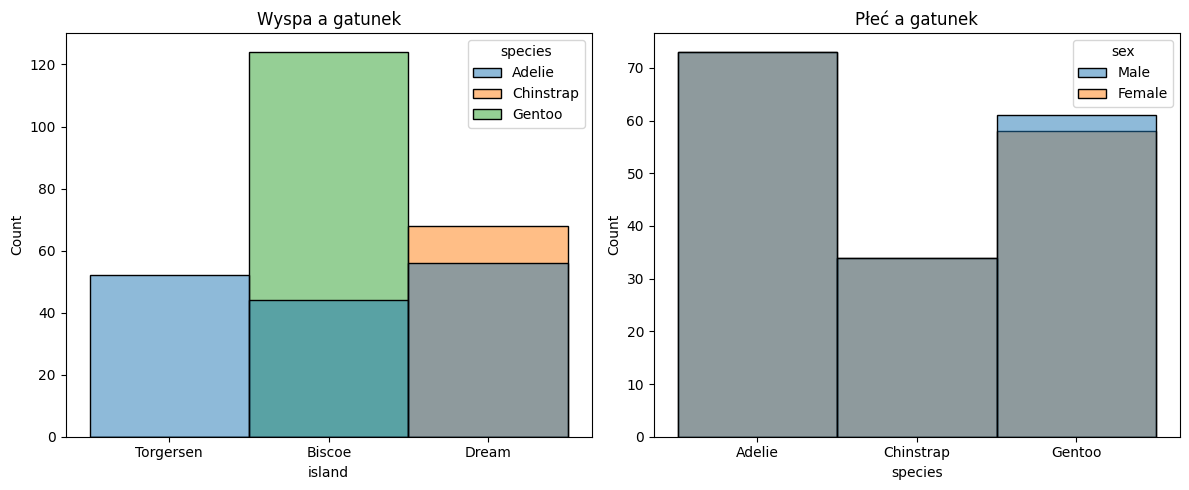

In [149]:
# wykresy zależności: gatunek-wyspa, gatunek-płeć
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=penguins, x="island", hue="species", bins=3, ax=axes[0])
axes[0].set_title("Wyspa a gatunek")
sns.histplot(data=penguins, x="species",  hue="sex", bins=3, ax=axes[1])
axes[1].set_title("Płeć a gatunek")
fig.tight_layout()
plt.show()

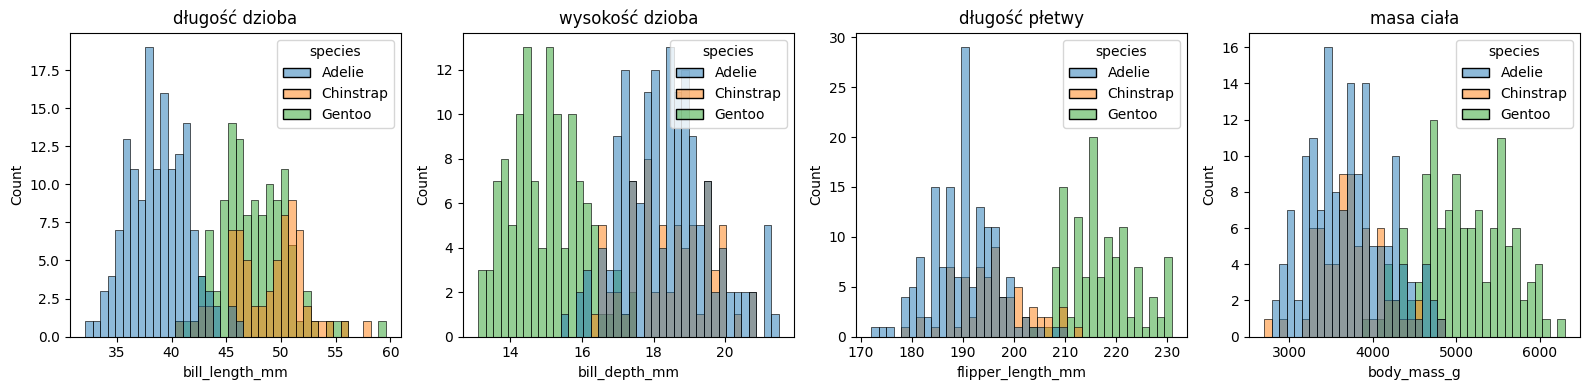

In [150]:
# wykresy zależności gatunku od cech liczbowych
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.histplot(data=penguins, x="bill_length_mm", hue="species", bins=40, ax=axes[0])
axes[0].set_title("długość dzioba")
sns.histplot(data=penguins, x="bill_depth_mm", hue="species", bins=40, ax=axes[1])
axes[1].set_title("wysokość dzioba")
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", bins=40, ax=axes[2])
axes[2].set_title("długość płetwy")
sns.histplot(data=penguins, x="body_mass_g", hue="species", bins=40, ax=axes[3])
axes[3].set_title("masa ciała")
fig.tight_layout()
plt.show()

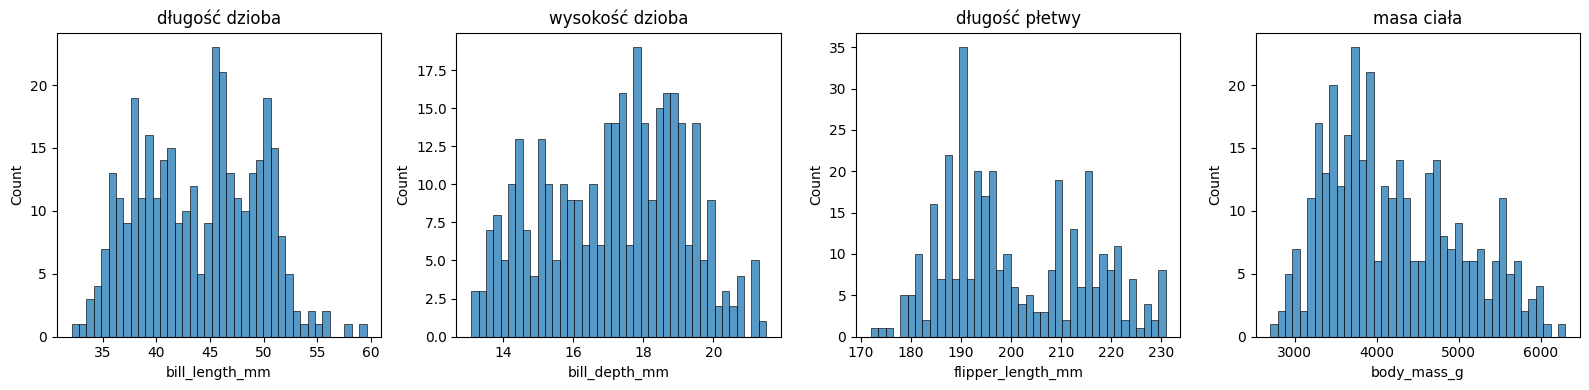

In [151]:
# badanie rozkładów bez rozdzielenia na gatunki
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.histplot(data=penguins, x="bill_length_mm", bins=40, ax=axes[0])
axes[0].set_title("długość dzioba")
sns.histplot(data=penguins, x="bill_depth_mm", bins=40, ax=axes[1])
axes[1].set_title("wysokość dzioba")
sns.histplot(data=penguins, x="flipper_length_mm", bins=40, ax=axes[2])
axes[2].set_title("długość płetwy")
sns.histplot(data=penguins, x="body_mass_g", bins=40, ax=axes[3])
axes[3].set_title("masa ciała")
fig.tight_layout()
plt.show()

**Wnioski z EDA, które zmieniają nasze dalsze decyzje:**
- klasy są lekko niezbalansowane (ok. 42% / 36% / 20%) → **baseline** "zawsze Adelie da ~ 0.44, stratify istotne (dzięki temu zachowane są proporcje klas/etykiet (Adelie, Chinstrap, Gentoo) pełnego zbioru w tworzonych podzbiorach: train, test),
- braki są bardzo małe (`sex` - 11,  kolumny pomiarowe - po 2.) → **imputacja** (wybór: pomiary -> mediana, `sex` -> najczęstsza wartość),
- `sex` i `island` są tekstowe → **kodowanie** (one-hot),
- cechy liczbowe mają różne skale → **standaryzacja**,
- Gentoo wyróżnia się od reszty 3. pomiarami, a Chinstrap i Adelie różnią się między sobą głównie długością dzioba → wszystkie pomiary są ważne,
- `island` mocno wiąże się z gatunkiem (Torgersen = tylko Adelie) → ważna cecha,
- nie usuwamy żadnych kolumn (braki są minimalne, brak kolumn-wycieków, brak duplikatów, tylko 2 wiersze bez pomiarów, dobre pod imputacje)
- skośność umiarkowana, nie transformujemy

---
## 3. Podział train / test

In [152]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]
features = num_features + cat_features
target = "species"


X_train, X_test, y_train, y_test = train_test_split(
    penguins[features], penguins[target],
    test_size=0.25,               # 25% do testu
    stratify=penguins[target],    # ten sam odsetek gatunków w train i w test
    random_state=42,              # seed - powtarzalny podział
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

(258, 6) (86, 6)
{'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}
{'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}


---
## 4. Przygotowanie danych: jak działa scikit-learn


### 4a. Braki: `SimpleImputer`

In [153]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[num_features])                        # fit: liczy medianę - TYLKO na train

print("wyuczone mediany:", imputer.statistics_)           # parametr wyuczony -> podkreślnik

test_num = imputer.transform(X_test[num_features])        # te same mediany do testu
print("braki w teście po transform:", np.isnan(test_num).sum())

wyuczone mediany: [  44.7   17.3  197.  4062.5]
braki w teście po transform: 0


### 4b. Kodowanie zmiennych tekstowych: `OneHotEncoder`

In [154]:
try:
    LogisticRegression().fit(X_train[["island"]], y_train)
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: 'Biscoe'


In [155]:
encoder = OneHotEncoder(handle_unknown="ignore")
encoder.fit(X_train[["island"]].dropna())
print("kategorie:", encoder.categories_)

example = pd.DataFrame({"island": ["Biscoe", "Dream", "Torgersen"]})
pd.DataFrame(encoder.transform(example).toarray(), index=example["island"],
             columns=encoder.get_feature_names_out())

kategorie: [array(['Biscoe', 'Dream', 'Torgersen'], dtype=object)]


,island_Biscoe,island_Dream,island_Torgersen
island,,,
Biscoe,1.0,0.0,0.0
Dream,0.0,1.0,0.0
Torgersen,0.0,0.0,1.0


### 4c. Skalowanie: `StandardScaler`

In [156]:
# kroki łączą się: wynik imputera (bez braków) trafia do scalera
train_num = imputer.transform(X_train[num_features])
scaler = StandardScaler().fit(train_num)        # fit: liczy średnią i odchylenie - TYLKO na train
print("średnie:", scaler.mean_.round(2))              # wyuczone parametry -> podkreślnik
print("odchylenia:", scaler.scale_.round(2))

test_num_s = scaler.transform(test_num)    # te same parametry dla testu
print("pierwsze 3 wiersze testu po skalowaniu:\n", test_num_s[:3].round(2))

średnie: [  44.12   17.16  200.86 4215.02]
odchylenia: [  5.51   2.01  13.9  798.04]
pierwsze 3 wiersze testu po skalowaniu:
 [[-0.39 -1.82  0.66 -0.08]
 [-0.59 -1.72  0.95  0.55]
 [-0.48  0.66  0.01 -0.27]]


### 4d. Wszystko razem: `ColumnTransformer` + `Pipeline`

In [157]:
preparation = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")),             cat_features),
])

model = make_pipeline(preparation, LogisticRegression())
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression())])

---
## 5. Trenowanie

In [158]:
model.fit(X_train, y_train)

# inspekcja: wyuczone parametry są dostępne wewnątrz pipeline'u
liczby = model.named_steps["columntransformer"].named_transformers_["liczby"]
print("mediany (z train):", liczby.named_steps["simpleimputer"].statistics_)

nazwy = model.named_steps["columntransformer"].get_feature_names_out()
wagi = pd.Series(model.named_steps["logisticregression"].coef_[0], index=nazwy).sort_values()
wagi.round(3)

mediany (z train): [  44.7   17.3  197.  4062.5]


,0
liczby__bill_length_mm,-2.325
liczby__flipper_length_mm,-0.545
kategorie__island_Dream,-0.538
kategorie__sex_Female,-0.434
kategorie__island_Biscoe,-0.110
liczby__body_mass_g,0.027
kategorie__sex_Male,0.434
kategorie__island_Torgersen,0.649
liczby__bill_depth_mm,0.984


---
## 6. Predykcja


In [159]:
y_pred = model.predict(X_test)
pred_proba = model.predict_proba(X_test)

preview = X_test.head(5).copy()
for i, species in enumerate(model.classes_):
  preview[f"p({species})"] = pred_proba[:5, i].round(2)
preview["predykcja"] = y_pred[:5]
preview["prawda"] = y_test.head(5).values
preview

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,p(Adelie),p(Chinstrap),p(Gentoo),predykcja,prawda
236,42.0,13.5,210.0,4150.0,Biscoe,Female,0.01,0.00,0.99,Gentoo,Gentoo
230,40.9,13.7,214.0,4650.0,Biscoe,Female,0.01,0.00,0.99,Gentoo,Gentoo
151,41.5,18.5,201.0,4000.0,Dream,Male,0.92,0.07,0.01,Adelie,Adelie
173,48.5,17.5,191.0,3400.0,Dream,Male,0.03,0.96,0.01,Chinstrap,Chinstrap
174,43.2,16.6,187.0,2900.0,Dream,Female,0.11,0.88,0.01,Chinstrap,Chinstrap


---
## 7. Ewaluacja

In [160]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

rule_adelie = np.where(X_test["island"] == "Torgersen", "Adelie", "Gentoo") # to jest slaba regula, bo reszta to Gentoo

most_common_species_by_island = y_train.groupby(X_train["island"]).agg(lambda s: s.mode()[0])
# {'Biscoe': 'Gentoo', 'Dream': 'Chinstrap', 'Torgersen': 'Adelie'}
rule_islands = X_test["island"].map(most_common_species_by_island)



results = pd.Series({
    "baseline (zawsze Adelie)": baseline.score(X_test, y_test),
    "reguła: Torgersen → Adelie, reszta → Gentoo": (rule_adelie == y_test).mean(),
    "reguła: najczęstszy gatunek na wyspie": (rule_islands == y_test).mean(),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
results.round(3)

,0
baseline (zawsze Adelie),0.442
"reguła: Torgersen → Adelie, reszta → Gentoo",0.488
reguła: najczęstszy gatunek na wyspie,0.686
pipeline – train,0.992
pipeline – test,1.000


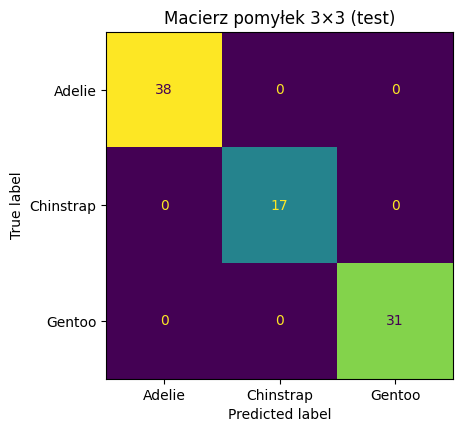

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [161]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=model.classes_),
                       display_labels=model.classes_).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek 3×3 (test)")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

---
## 8. Iteracja

In [162]:
def build(num, cat, add_indicator=False):

    transformers = [("liczby",
                     make_pipeline(SimpleImputer(strategy="median", add_indicator=add_indicator),
                                   StandardScaler()),
                     num)]
    if cat:
        transformers.append(("kategorie",
                             make_pipeline(SimpleImputer(strategy="most_frequent"),
                                                        OneHotEncoder(handle_unknown="ignore")),
                             cat))
    prep = ColumnTransformer(transformers)
    return make_pipeline(prep, LogisticRegression(max_iter=1000))



variants = {
    "pełny":                  build(num_features, cat_features),
    "+ flagi braków":         build(num_features, cat_features, add_indicator=True),
    "bez wyspy":              build(num_features, ["sex"]),
    "bez płci":               build(num_features, ["island"]),
    "bez wyspy i płci":       build(num_features, []),
    "bez masy":               build([c for c in num_features if c != "body_mass_g"], cat_features),
    "tylko dziób (2 cechy)":  build(["bill_length_mm", "bill_depth_mm"], []),
}

pd.Series({name: m.fit(X_train, y_train).score(X_test, y_test) for name, m in variants.items()}).round(3)


,0
pełny,1.000
+ flagi braków,1.000
bez wyspy,1.000
bez płci,1.000
bez wyspy i płci,1.000
bez masy,0.988
tylko dziób (2 cechy),0.942
